<a href="https://colab.research.google.com/github/alifanaura/pengolahan-citra-digital/blob/main/Tugas-3/PCD_Assignment03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

image_path = '/content/drive/MyDrive/PCD_Assignment03/garden.png'

if os.path.exists(image_path):
    print("Image found!")
    print("Path:", image_path)
else:
    print("Image not found!")

Image found!
Path: /content/drive/MyDrive/PCD_Assignment03/garden.png


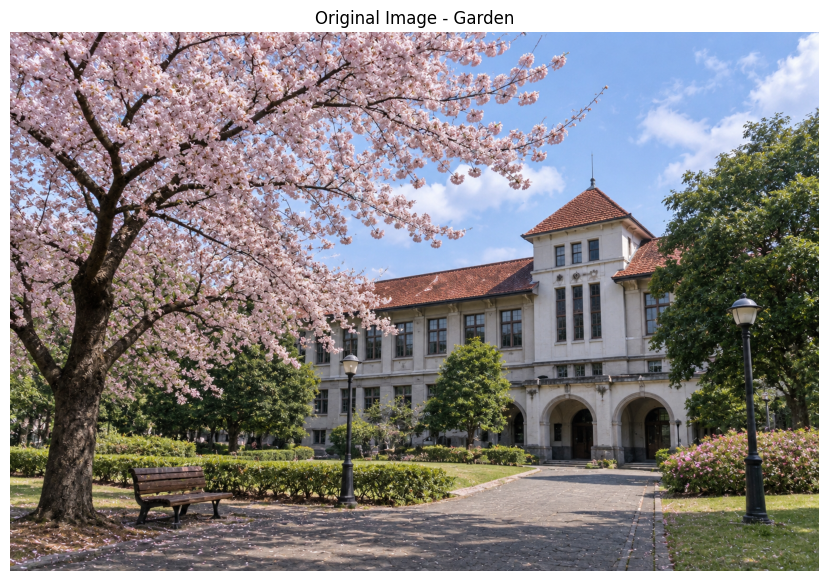

Image shape: (1024, 1536, 3)


In [ ]:
import cv2
import matplotlib.pyplot as plt

# Membaca gambar
img = cv2.imread(image_path)

# Mengubah BGR menjadi RGB
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Menampilkan gambar
plt.figure(figsize=(12, 7))
plt.imshow(img)
plt.title("Original Image - Garden")
plt.axis('off')
plt.show()

print("Image shape:", img.shape)

K-Means Clustering

In [ ]:
import numpy as np

# Mengubah gambar menjadi array pixel
pixels = img.reshape((-1, 3)).astype(np.float64)

# Jumlah cluster
K = 5

# Inisialisasi centroid secara merata
np.random.seed(42)
random_indices = np.random.choice(
    len(pixels), K, replace=False
)

centroids = pixels[random_indices]

print("Jumlah pixels:", len(pixels))
print("Jumlah cluster:", K)
print("Centroid awal:")
print(centroids)

Jumlah pixels: 1572864
Jumlah cluster: 5
Centroid awal:
[[180. 150. 170.]
 [166. 148. 166.]
 [184. 149. 149.]
 [174. 203. 245.]
 [ 82.  47.  49.]]


In [ ]:
# Iterasi K-Means
max_iterations = 10

for iteration in range(max_iterations):

    # Menghitung jarak setiap pixel ke centroid
    distances = np.linalg.norm(
        pixels[:, np.newaxis] - centroids,
        axis=2
    )

    # Menentukan cluster terdekat
    labels = np.argmin(distances, axis=1)

    # Menghitung ulang centroid
    new_centroids = np.zeros((K, 3))

    for k in range(K):
        cluster_pixels = pixels[labels == k]

        if len(cluster_pixels) > 0:
            new_centroids[k] = np.mean(
                cluster_pixels, axis=0
            )
        else:
            new_centroids[k] = centroids[k]

    # Menghitung perubahan centroid
    difference = np.linalg.norm(
        new_centroids - centroids
    )

    centroids = new_centroids

    print(
        f"Iteration {iteration + 1}: "
        f"Centroid change = {difference:.4f}"
    )

    if difference < 0.01:
        break

print("\nFinal Centroids:")
print(centroids)

Iteration 1: Centroid change = 62.5442
Iteration 2: Centroid change = 24.4375
Iteration 3: Centroid change = 21.1669
Iteration 4: Centroid change = 23.1468
Iteration 5: Centroid change = 15.8344
Iteration 6: Centroid change = 10.0201
Iteration 7: Centroid change = 6.7964
Iteration 8: Centroid change = 4.9988
Iteration 9: Centroid change = 3.9233
Iteration 10: Centroid change = 3.2372

Final Centroids:
[[186.64741601 167.51660322 167.31813908]
 [ 96.48281502  88.84402787  77.56468556]
 [149.06003069 130.21330841 123.48425722]
 [180.75778126 200.03468227 237.57611143]
 [ 39.77395274  39.412642    28.27936236]]


Segmentation Result

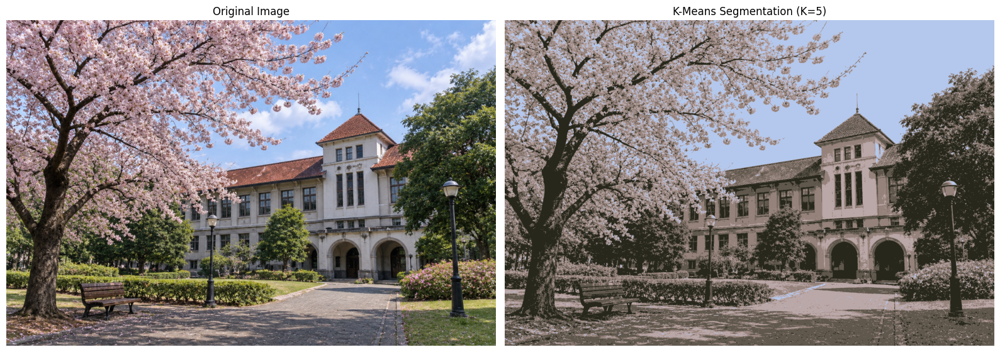

In [ ]:
# Menghitung ulang label berdasarkan centroid final
distances = np.linalg.norm(
    pixels[:, np.newaxis] - centroids,
    axis=2
)

labels = np.argmin(distances, axis=1)

# Membentuk segmented image
segmented_pixels = centroids[labels]

segmented_image = segmented_pixels.reshape(img.shape)
segmented_image = np.clip(
    segmented_image, 0, 255
).astype(np.uint8)

# Menampilkan perbandingan gambar
plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented_image)
plt.title("K-Means Segmentation (K=5)")
plt.axis('off')

plt.tight_layout()
plt.show()

Cluster Distribution Analysis

In [ ]:
# Menghitung jumlah pixel setiap cluster
unique_labels, counts = np.unique(
    labels, return_counts=True
)

for cluster, count in zip(unique_labels, counts):
    percentage = (count / len(pixels)) * 100

    print(
        f"Cluster {cluster}: "
        f"{count} pixels ({percentage:.2f}%)"
    )

Cluster 0: 246994 pixels (15.70%)
Cluster 1: 344613 pixels (21.91%)
Cluster 2: 311152 pixels (19.78%)
Cluster 3: 304924 pixels (19.39%)
Cluster 4: 365181 pixels (23.22%)


Cluster Distribution Visualization

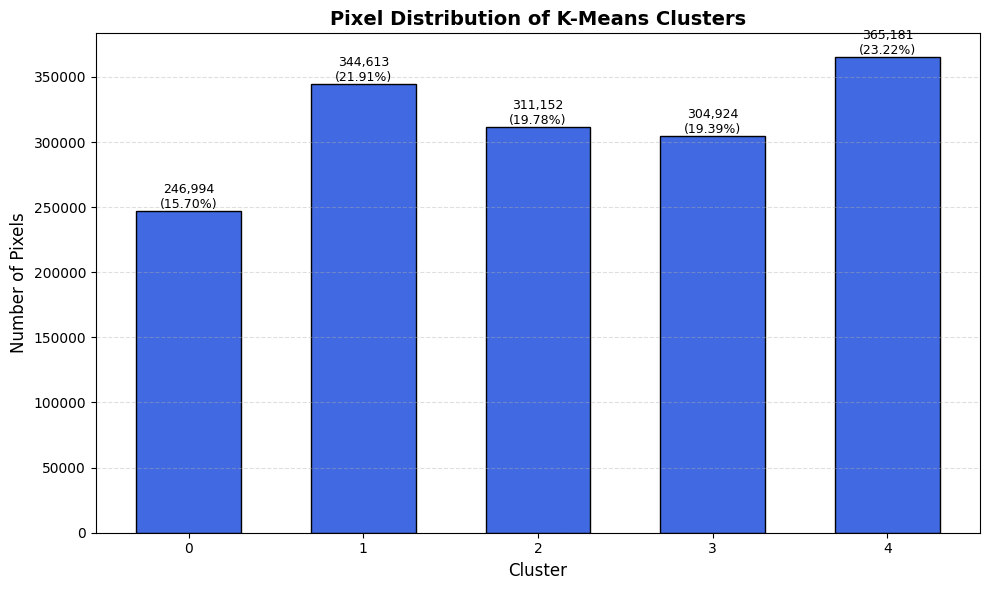

In [21]:
import matplotlib.pyplot as plt

# Menghitung persentase setiap cluster
percentages = (counts / len(pixels)) * 100

# Membuat bar chart
plt.figure(figsize=(10, 6))

bars = plt.bar(
    unique_labels,
    counts,
    color='royalblue',
    edgecolor='black',
    width=0.6
)

# Menambahkan nilai di atas setiap batang
for bar, count, percentage in zip(bars, counts, percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{count:,}\n({percentage:.2f}%)',
        ha='center',
        va='bottom',
        fontsize=9
    )

# Pengaturan grafik
plt.title('Pixel Distribution of K-Means Clusters',
          fontsize=14, fontweight='bold')

plt.xlabel('Cluster', fontsize=12)
plt.ylabel('Number of Pixels', fontsize=12)

plt.xticks(unique_labels)
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

Binary Mask Generation

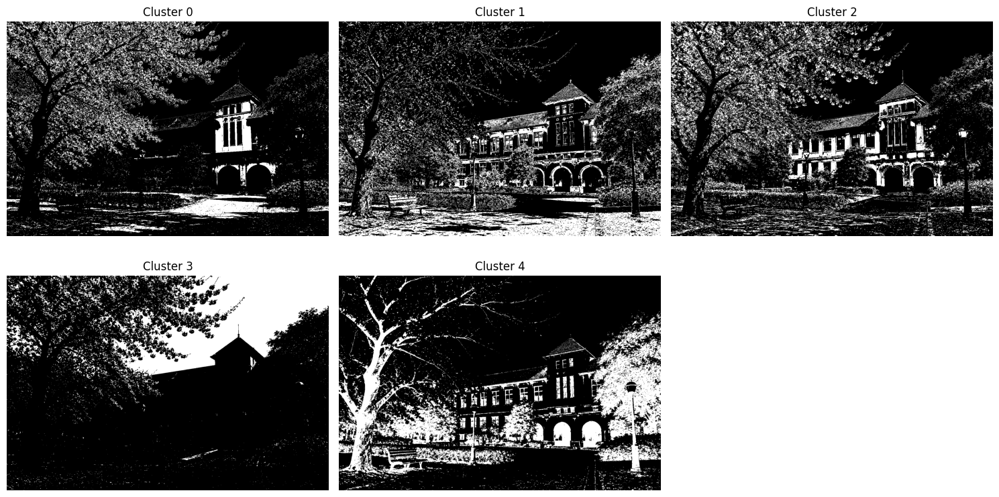

In [ ]:
# Membuat binary mask untuk setiap cluster
binary_masks = []

for k in range(K):
    mask = (labels.reshape(img.shape[:2]) == k).astype(np.uint8) * 255
    binary_masks.append(mask)

# Menampilkan seluruh binary mask
plt.figure(figsize=(15, 8))

for k in range(K):
    plt.subplot(2, 3, k + 1)
    plt.imshow(binary_masks[k], cmap='gray')
    plt.title(f"Cluster {k}")
    plt.axis('off')

plt.tight_layout()
plt.show()

Structuring Element Definition

In [ ]:
# Define a 3x3 square structuring element
kernel = np.ones((3, 3), dtype=np.uint8)

print("Structuring Element:")
print(kernel)

Structuring Element:
[[1 1 1]
 [1 1 1]
 [1 1 1]]


Dilation

In [ ]:
def dilation(image, kernel):
    h, w = image.shape
    kh, kw = kernel.shape

    pad_h = kh // 2
    pad_w = kw // 2

    padded = np.pad(
        image,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode='constant',
        constant_values=0
    )

    output = np.zeros_like(image)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]

            if np.any(region[kernel == 1] == 255):
                output[i, j] = 255

    return output

Applying Dilation

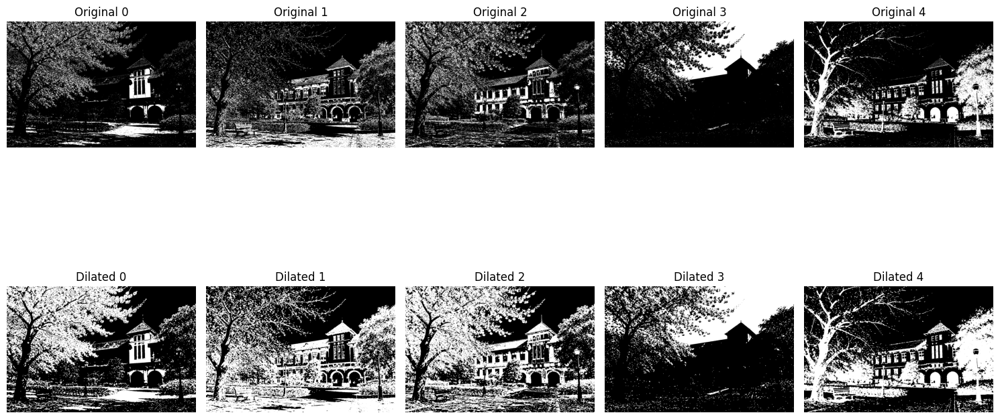

In [ ]:
# Apply dilation to all binary masks
dilated_masks = []

for mask in binary_masks:
    dilated = dilation(mask, kernel)
    dilated_masks.append(dilated)

# Display original and dilated masks
plt.figure(figsize=(15, 10))

for k in range(K):
    plt.subplot(2, 5, k + 1)
    plt.imshow(binary_masks[k], cmap='gray')
    plt.title(f"Original {k}")
    plt.axis('off')

    plt.subplot(2, 5, k + 6)
    plt.imshow(dilated_masks[k], cmap='gray')
    plt.title(f"Dilated {k}")
    plt.axis('off')

plt.tight_layout()
plt.show()

Erosion

In [ ]:
def erosion(image, kernel):
    h, w = image.shape
    kh, kw = kernel.shape

    pad_h = kh // 2
    pad_w = kw // 2

    padded = np.pad(
        image,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode='constant',
        constant_values=0
    )

    output = np.zeros_like(image)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]

            if np.all(region[kernel == 1] == 255):
                output[i, j] = 255

    return output

Applying Erosion

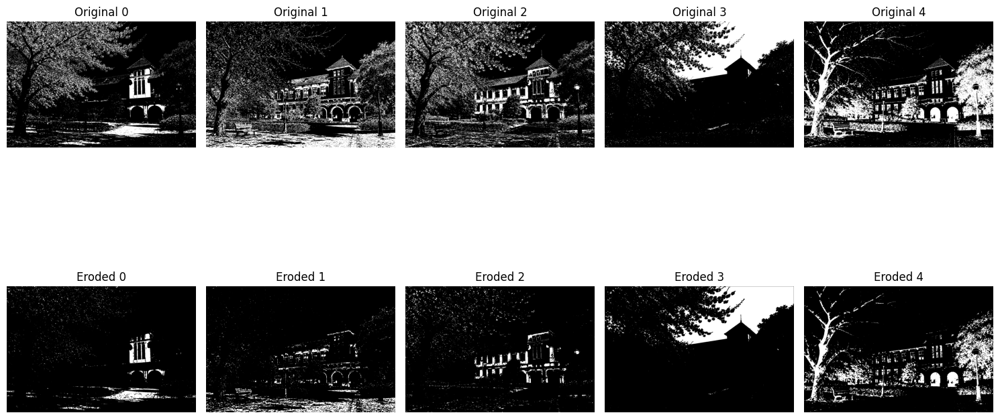

In [ ]:
# Apply erosion to all binary masks
eroded_masks = []

for mask in binary_masks:
    eroded = erosion(mask, kernel)
    eroded_masks.append(eroded)

# Display original and eroded masks
plt.figure(figsize=(15, 10))

for k in range(K):
    plt.subplot(2, 5, k + 1)
    plt.imshow(binary_masks[k], cmap='gray')
    plt.title(f"Original {k}")
    plt.axis('off')

    plt.subplot(2, 5, k + 6)
    plt.imshow(eroded_masks[k], cmap='gray')
    plt.title(f"Eroded {k}")
    plt.axis('off')

plt.tight_layout()
plt.show()

Opening

In [ ]:
def opening(image, kernel):
    eroded = erosion(image, kernel)
    opened = dilation(eroded, kernel)

    return opened

Applying Opening

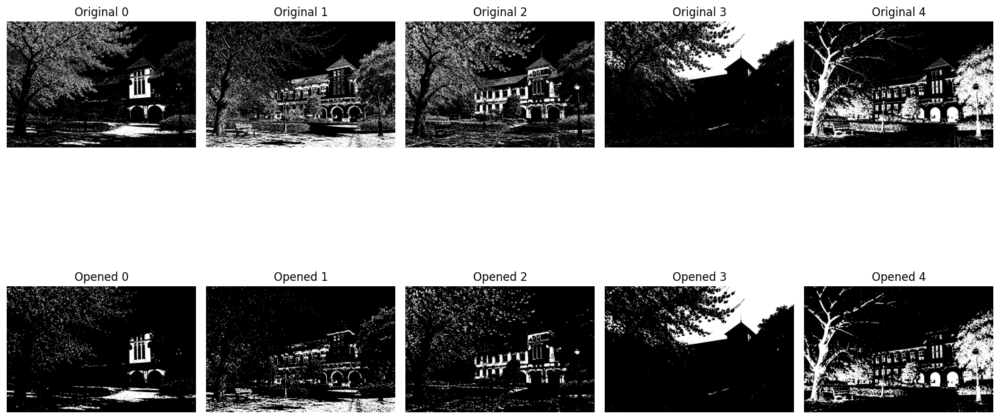

In [17]:
# Apply opening to all binary masks
opened_masks = []

for mask in binary_masks:
    opened = opening(mask, kernel)
    opened_masks.append(opened)

# Display original and opened masks
plt.figure(figsize=(15, 10))

for k in range(K):
    plt.subplot(2, 5, k + 1)
    plt.imshow(binary_masks[k], cmap='gray')
    plt.title(f"Original {k}")
    plt.axis('off')

    plt.subplot(2, 5, k + 6)
    plt.imshow(opened_masks[k], cmap='gray')
    plt.title(f"Opened {k}")
    plt.axis('off')

plt.tight_layout()
plt.show()

Closing

In [18]:
def closing(image, kernel):
    dilated = dilation(image, kernel)
    closed = erosion(dilated, kernel)

    return closed

Applying Closing

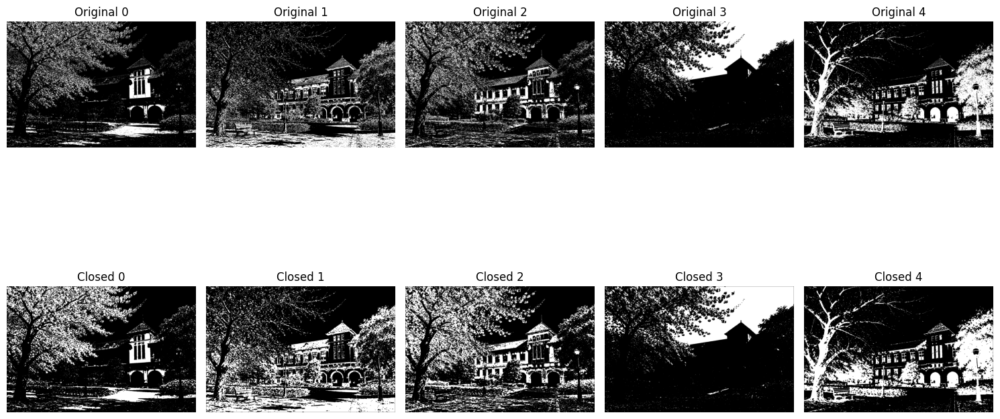

In [19]:
# Apply closing to all binary masks
closed_masks = []

for mask in binary_masks:
    closed = closing(mask, kernel)
    closed_masks.append(closed)

# Display original and closed masks
plt.figure(figsize=(15, 10))

for k in range(K):
    plt.subplot(2, 5, k + 1)
    plt.imshow(binary_masks[k], cmap='gray')
    plt.title(f"Original {k}")
    plt.axis('off')

    plt.subplot(2, 5, k + 6)
    plt.imshow(closed_masks[k], cmap='gray')
    plt.title(f"Closed {k}")
    plt.axis('off')

plt.tight_layout()
plt.show()

Comparison of Morphological Operations

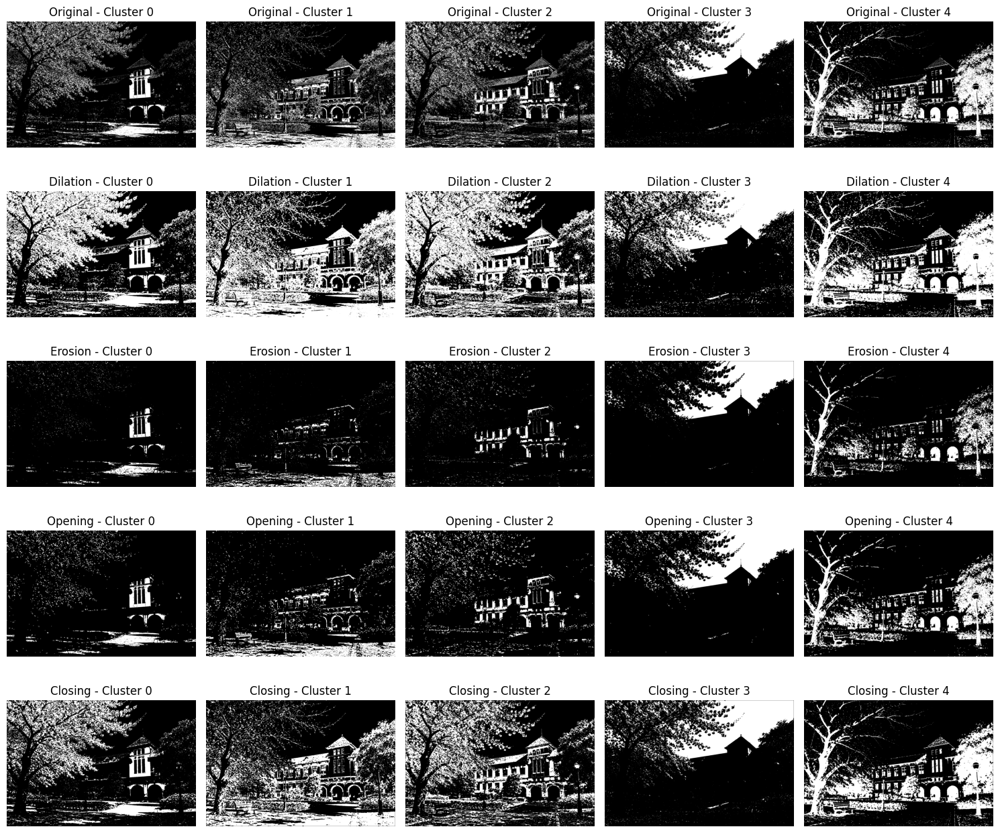

In [20]:
operation_results = [
    binary_masks,
    dilated_masks,
    eroded_masks,
    opened_masks,
    closed_masks
]

operation_names = [
    "Original",
    "Dilation",
    "Erosion",
    "Opening",
    "Closing"
]

fig, axes = plt.subplots(5, K, figsize=(15, 13))

for row, (operation, name) in enumerate(
    zip(operation_results, operation_names)
):
    for col in range(K):
        axes[row, col].imshow(operation[col], cmap='gray')
        axes[row, col].set_title(
            f"{name} - Cluster {col}"
        )
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

Quantitative Comparison of Morphological Operations

In [24]:
# Pixel count data for each cluster
data = {
    0: [224396, 531714, 44863, 84687, 326485],
    1: [358607, 745666, 97779, 176407, 500945],
    2: [328806, 741888, 63881, 129754, 489815],
    3: [287343, 395701, 223212, 253101, 305454],
    4: [373712, 563810, 210985, 309148, 430823]
}

operations = ["Original", "Dilation", "Erosion", "Opening", "Closing"]

# Display comparison table
print("QUANTITATIVE COMPARISON OF MORPHOLOGICAL OPERATIONS\n")

header = (
    f"{'Cluster':<10}"
    f"{'Original':>12}"
    f"{'Dilation':>12}"
    f"{'Erosion':>12}"
    f"{'Opening':>12}"
    f"{'Closing':>12}"
)

print(header)

for cluster, values in data.items():
    print(
        f"{cluster:<10}"
        f"{values[0]:>12,}"
        f"{values[1]:>12,}"
        f"{values[2]:>12,}"
        f"{values[3]:>12,}"
        f"{values[4]:>12,}"
    )

# Calculate percentage changes
print("\nPERCENTAGE CHANGE ANALYSIS")

for cluster, values in data.items():

    original = values[0]

    print(f"\nCluster {cluster}")

    for i in range(1, len(operations)):
        percentage = ((values[i] - original) / original) * 100

        print(
            f"{operations[i]:<10}: "
            f"{values[i]:,} pixels "
            f"({percentage:+.2f}%)"
        )

print("\nAnalysis Completed.")

QUANTITATIVE COMPARISON OF MORPHOLOGICAL OPERATIONS

Cluster       Original    Dilation     Erosion     Opening     Closing
0              224,396     531,714      44,863      84,687     326,485
1              358,607     745,666      97,779     176,407     500,945
2              328,806     741,888      63,881     129,754     489,815
3              287,343     395,701     223,212     253,101     305,454
4              373,712     563,810     210,985     309,148     430,823

PERCENTAGE CHANGE ANALYSIS

Cluster 0
Dilation  : 531,714 pixels (+136.95%)
Erosion   : 44,863 pixels (-80.01%)
Opening   : 84,687 pixels (-62.26%)
Closing   : 326,485 pixels (+45.50%)

Cluster 1
Dilation  : 745,666 pixels (+107.93%)
Erosion   : 97,779 pixels (-72.73%)
Opening   : 176,407 pixels (-50.81%)
Closing   : 500,945 pixels (+39.69%)

Cluster 2
Dilation  : 741,888 pixels (+125.63%)
Erosion   : 63,881 pixels (-80.57%)
Opening   : 129,754 pixels (-60.54%)
Closing   : 489,815 pixels (+48.97%)

Cluster 3
Dilati